In [7]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from build_lagged_features import read_table, build_lagged_frame
import matplotlib.pyplot as plt

### Lagt till: 
- clean outliers
- Ta bort noise
- Ta bort features som korrelerar med varandra (utom de som korrelerar med klorofyll)
- Lagt till ett validerings-sett, där olika lamda testas

### Data cleaning functions

In [8]:
def remove_noise_features(df, target, training_data, min_corr=0.1):
    df_no_noise = df.copy()
    corr_matrix = df_no_noise.loc[training_data].corr(numeric_only=True).abs()
    noise_features = corr_matrix.index[corr_matrix[target] < min_corr].tolist()
    if target in noise_features:
        noise_features.remove(target)
    return df_no_noise.drop(columns=noise_features)

def remove_correlated_features(df, target, training_data, max_corr=0.9):
    df_no_correlation = df.copy()
    feature_cols = [c for c in df_no_correlation.columns if c not in ['date', target]]
    corr_matrix = df_no_correlation.loc[training_data, feature_cols].corr(numeric_only=True).abs()
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    correlated_features = [col for col in upper.columns if any(upper[col] > max_corr)]
    if target in correlated_features:
        correlated_features.remove(target)
    return df_no_correlation.drop(columns=correlated_features)

def clean_outliers(df, target, training_data, k=6, window=10):
    df_cleaned = df.copy()
    train_mad = np.abs(df_cleaned.loc[training_data, target] - df_cleaned.loc[training_data, target].median()).median()
    rolling_median = df_cleaned[target].rolling(window=window, center=True, min_periods=1).median()
    outlier = (np.abs(df_cleaned[target] - rolling_median) > k * train_mad) & training_data
    df_cleaned.loc[outlier, target] = rolling_median[outlier]
    return df_cleaned


### Preparing data and variables

In [9]:
# Read data and define variables
raw = read_table("chlorophyll_student_2015_2023.xlsx")
target = 'chlorophyll_a_mg_m3'

train_start, train_end = '2015-01-01', '2019-12-31'
validation_start, validation_end = '2020-01-01', '2021-12-31'
test_start, test_end = '2022-01-01', '2023-12-31'

# Make lagged features
df_lagged = build_lagged_frame(raw)
train_dates = (df_lagged['date'] >= train_start) & (df_lagged['date'] <= train_end)

# Use cleaning functions on lagged data (only training!!)
df_cleaned = clean_outliers(remove_correlated_features(remove_noise_features(df_lagged, target, train_dates),target, train_dates),target, train_dates)

# Make sure its the right dtype and sort by date
df_cleaned['date'] = pd.to_datetime(df_cleaned['date'])
df_cleaned = df_cleaned.sort_values('date').set_index('date')

Y = df_cleaned[target]
X = df_cleaned.drop(columns=[target])

X_train, Y_train = X.loc[train_start:train_end], Y.loc[train_start:train_end]
X_val, Y_val = X.loc[validation_start:validation_end], Y.loc[validation_start:validation_end]
X_test, Y_test = X.loc[test_start:test_end], Y.loc[test_start:test_end]

# Normalization (only on training data)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled   = scaler.transform(X_val)
X_test_scaled  = scaler.transform(X_test)

### Training models with validation data

In [13]:
validation_results = []

# Linear Regression
LR = LinearRegression().fit(X_train_scaled, Y_train)
Y_pred_val_LR = LR.predict(X_val_scaled)

validation_results.append({
    'Modell': 'Linear Regression', 'Alpha': '-',
    'Val R2': r2_score(Y_val, Y_pred_val_LR),
    'Val RMSE': np.sqrt(mean_squared_error(Y_val, Y_pred_val_LR)),
    'Val MAE': mean_absolute_error(Y_val, Y_pred_val_LR)
})

# Ridge Regression, testing different lambda values 
for a in [0.01, 0.1, 1, 10, 50, 100]:
    model_ridge = Ridge(alpha = a).fit(X_train_scaled, Y_train)
    prediction_ridge = model_ridge.predict(X_val_scaled)
    validation_results.append({
        'Modell': 'Ridge', 'Alpha': a,
        'Val R2': r2_score(Y_val, prediction_ridge),
        'Val RMSE': np.sqrt(mean_squared_error(Y_val, prediction_ridge)),
        'Val MAE': mean_absolute_error(Y_val, prediction_ridge)
    })

# Lasso Regression, testing different lambda values
for a in [0.0001, 0.001, 0.005, 0.01, 0.05, 0.1, 0.5]:
    model_lasso = Lasso(alpha=a).fit(X_train_scaled, Y_train)
    prediction_lasso = model_lasso.predict(X_val_scaled)
    validation_results.append({
        'Modell': 'Lasso', 'Alpha': a,
        'Val R2': r2_score(Y_val, prediction_lasso),
        'Val RMSE': np.sqrt(mean_squared_error(Y_val, prediction_lasso)),
        'Val MAE': mean_absolute_error(Y_val, prediction_lasso)
    })

# Create a DataFrame to summarize the validation results
df_val = pd.DataFrame(validation_results).sort_values('Val RMSE').reset_index(drop=True)
best_ridge_alpha = df_val[df_val['Modell'] == 'Ridge'].iloc[0]['Alpha']
best_lasso_alpha = df_val[df_val['Modell'] == 'Lasso'].iloc[0]['Alpha']

print('Validation results:')
print(df_val.head(5).to_string(index=False))
print(f'\nOptimal Ridge alpha/lambda: {best_ridge_alpha}')
print(f'Optimal Lasso alpha/lambda: {best_lasso_alpha}')

Validation results:
Modell  Alpha   Val R2  Val RMSE  Val MAE
 Lasso  0.001 0.726904  0.338330 0.197479
 Lasso  0.005 0.726496  0.338583 0.197417
 Lasso   0.01 0.725026  0.339491 0.197804
 Ridge    100 0.723905  0.340182 0.202399
 Ridge     50 0.723630  0.340352 0.201296

Optimal Ridge alpha/lambda: 100
Optimal Lasso alpha/lambda: 0.001


C:\Users\ellen\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.912468e+00, tolerance: 6.118e-02
  model = cd_fast.enet_coordinate_descent(


### Test models on test data

Final model performance summary:
             Modell  Train RMSE  Train R2  Val RMSE  Val R2  Test RMSE  Test R2  Test MAE
  Linear Regression      0.2608    0.7985    0.3420  0.7209     0.4171   0.6204    0.1969
  Ridge (alpha=100)      0.2632    0.7948    0.3402  0.7239     0.4143   0.6256    0.1970
Lasso (alpha=0.001)      0.2621    0.7966    0.3383  0.7269     0.4142   0.6258    0.1942


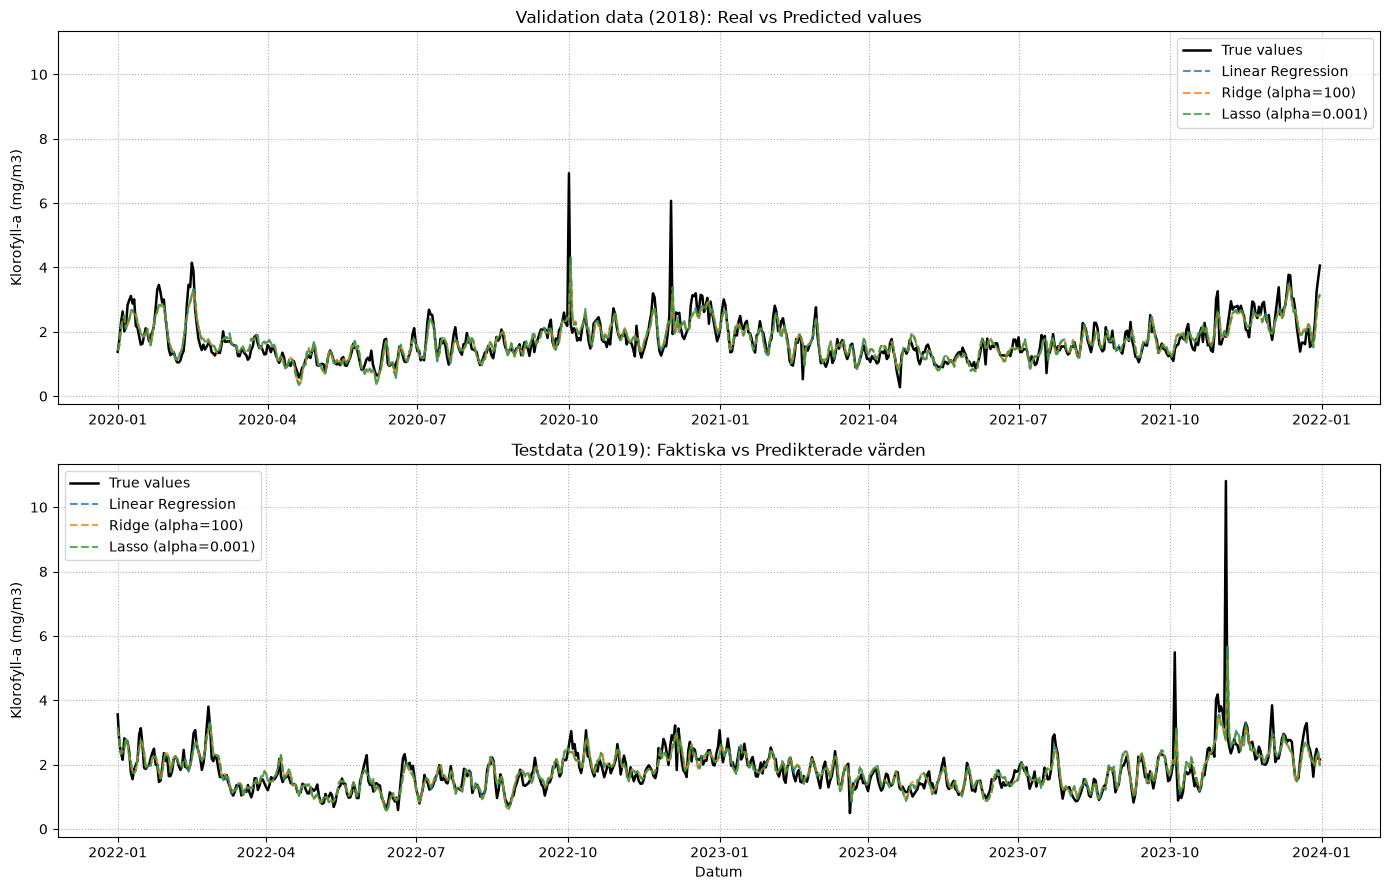

In [14]:

final_LR  = LinearRegression().fit(X_train_scaled, Y_train)
p_train_LR = final_LR.predict(X_train_scaled)
p_val_LR   = final_LR.predict(X_val_scaled)
p_test_LR  = final_LR.predict(X_test_scaled)

final_ridge = Ridge(alpha=best_ridge_alpha).fit(X_train_scaled, Y_train)
p_train_ridge = final_ridge.predict(X_train_scaled)
p_val_ridge   = final_ridge.predict(X_val_scaled)
p_test_ridge  = final_ridge.predict(X_test_scaled)

final_lasso = Lasso(alpha=best_lasso_alpha).fit(X_train_scaled, Y_train)
p_train_lasso = final_lasso.predict(X_train_scaled)
p_val_lasso   = final_lasso.predict(X_val_scaled)
p_test_lasso  = final_lasso.predict(X_test_scaled)

predictions = {
    'Linear Regression': (p_train_LR, p_val_LR, p_test_LR),
    f'Ridge (alpha={best_ridge_alpha})': (p_train_ridge, p_val_ridge, p_test_ridge),
    f'Lasso (alpha={best_lasso_alpha})': (p_train_lasso, p_val_lasso, p_test_lasso)
}

final_summary = []
for name, (p_tr, p_v, p_te) in predictions.items():
    final_summary.append({
        'Modell': name,
        'Train RMSE': np.sqrt(mean_squared_error(Y_train, p_tr)),
        'Train R2': r2_score(Y_train, p_tr),
        'Val RMSE': np.sqrt(mean_squared_error(Y_val, p_v)),
        'Val R2': r2_score(Y_val, p_v),
        'Test RMSE': np.sqrt(mean_squared_error(Y_test, p_te)),
        'Test R2': r2_score(Y_test, p_te),
        'Test MAE': mean_absolute_error(Y_test, p_te)
    })

df_final = pd.DataFrame(final_summary)
print("Final model performance summary:")
print(df_final.round(4).to_string(index=False))

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharey=True)

axes[0].plot(Y_val.index, Y_val, label='True values', color='black', linewidth=1.8)
for name, (_, p_v, _) in predictions.items():
    axes[0].plot(Y_val.index, p_v, label=name, linestyle='--', alpha=0.8)
axes[0].set_title('Validation data (2018): Real vs Predicted values')
axes[0].set_ylabel('Klorofyll-a (mg/m3)')
axes[0].grid(True, linestyle=':')
axes[0].legend()

axes[1].plot(Y_test.index, Y_test, label='True values', color='black', linewidth=1.8)
for name, (_, _, p_te) in predictions.items():
    axes[1].plot(Y_test.index, p_te, label=name, linestyle='--', alpha=0.8)
axes[1].set_title('Testdata (2019): Faktiska vs Predikterade värden')
axes[1].set_xlabel('Datum')
axes[1].set_ylabel('Klorofyll-a (mg/m3)')
axes[1].grid(True, linestyle=':')
axes[1].legend()
plt.tight_layout()
plt.show()

